# 03A — Review the five-video tracked-pose pilot

This is a **read-only review** of the five NPZ files created by `03_tracked_pose_extraction_IOU.ipynb`.

It does not run YOLO or ViTPose, does not change the NPZ files, and does not modify Notebook 1. It draws the selected target person's saved bounding box and 17-joint skeleton on a few original video frames.

Use this review before enabling full extraction. Pay special attention to `Rowing`, where the pilot reported a low pose-success rate and many temporary track IDs.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
NOTEBOOK2_DIR = PROJECT_DIR / "Notebook_2_Improved_v2"
TRACKED_DIR = NOTEBOOK2_DIR / "data" / "tracked_keypoints_iou_v3"
REPORT_PATH = (NOTEBOOK2_DIR / "outputs" / "reports" /
               "tracked_pose_extraction_iou_v3" / "tracked_pose_extraction_report.csv")
REVIEW_DIR = NOTEBOOK2_DIR / "outputs" / "visualizations" / "tracked_pose_pilot_review_v1"
REVIEW_DIR.mkdir(parents=True, exist_ok=True)

assert TRACKED_DIR.is_dir(), f"Tracked NPZ folder not found: {TRACKED_DIR}"
assert REPORT_PATH.is_file(), f"Extraction report not found: {REPORT_PATH}"

report = pd.read_csv(REPORT_PATH)
report = report[report["status"].astype(str).eq("success")].copy()
print("Successful pilot videos:", len(report))
print("Tracked NPZ folder:", TRACKED_DIR)
print("Review output folder:", REVIEW_DIR)


Successful pilot videos: 5
Tracked NPZ folder: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\data\tracked_keypoints_iou_v3
Review output folder: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\visualizations\tracked_pose_pilot_review_v1


In [2]:
# Show the pilot summary in a compact table.
summary_cols = [c for c in [
    "label", "decoded_frames", "sampled_frames", "pose_successes",
    "pose_success_rate", "tracked_ids", "target_track_id",
    "all_person_observations", "complete_video", "worker_return_code"
] if c in report.columns]
display(report[summary_cols].to_string(index=False))

# COCO-17 skeleton connections (joint indices match the ViTPose COCO output).
COCO_EDGES = [
    (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
    (5, 11), (6, 12), (11, 12), (11, 13), (13, 15),
    (12, 14), (14, 16), (0, 1), (0, 2), (1, 3),
    (2, 4), (0, 5), (0, 6)
]


'            label  decoded_frames  sampled_frames  pose_successes  pose_success_rate  tracked_ids  target_track_id  all_person_observations  complete_video  worker_return_code\n           Typing             120              30              30           1.000000            1                1                       30           False                   0\n         Knitting             120              30              29           0.966667            2                2                       31           False                   0\nBoxingPunchingBag             120              30              27           0.900000            7                1                       43           False                   0\n           Biking             120              30              28           0.933333            4                1                       32           False                   0\n           Rowing             120              30               9           0.300000           21                2

In [3]:
def render_video_review(row, max_frames=6):
    npz_path = Path(str(row["output_path"]))
    video_path = Path(str(row["video_path"]))
    if not npz_path.is_file():
        print("Missing NPZ:", npz_path)
        return None
    if not video_path.is_file():
        print("Missing source video:", video_path)
        return None

    with np.load(npz_path, allow_pickle=False) as d:
        keypoints = np.asarray(d["keypoints"], dtype=np.float32)
        boxes = np.asarray(d["boxes"], dtype=np.float32)
        frame_indices = np.asarray(d["frame_indices"], dtype=np.int32)
        has_person = np.asarray(d["has_person"], dtype=bool)
        track_ids = np.asarray(d["track_ids"], dtype=np.int64)
        target_id = int(d["target_track_id"].item())
        all_track_ids = np.asarray(d["all_track_ids"], dtype=np.int64)
        complete_video = bool(d["complete_video"].item())
        decoded_frames = int(d["decoded_frames"].item())

    valid_positions = np.flatnonzero(has_person)
    if len(valid_positions) == 0:
        print(f"{row['label']}: no valid target poses saved")
        return None

    take = np.linspace(0, len(valid_positions) - 1,
                       min(max_frames, len(valid_positions)), dtype=int)
    chosen = valid_positions[take]

    cap = cv2.VideoCapture(str(video_path))
    frames = []
    try:
        for pos in chosen:
            source_index = int(frame_indices[pos])
            cap.set(cv2.CAP_PROP_POS_FRAMES, source_index)
            ok, bgr = cap.read()
            if not ok:
                frames.append(None)
                continue

            canvas = bgr.copy()
            if np.isfinite(boxes[pos]).all():
                x1, y1, x2, y2 = np.round(boxes[pos]).astype(int)
                cv2.rectangle(canvas, (x1, y1), (x2, y2), (0, 255, 0), 2)

            kp = keypoints[pos]
            point_valid = np.isfinite(kp[:, :2]).all(axis=1)
            for a, b in COCO_EDGES:
                if point_valid[a] and point_valid[b]:
                    pa = tuple(np.round(kp[a, :2]).astype(int))
                    pb = tuple(np.round(kp[b, :2]).astype(int))
                    cv2.line(canvas, pa, pb, (0, 200, 255), 2)
            for j in np.flatnonzero(point_valid):
                point = tuple(np.round(kp[j, :2]).astype(int))
                cv2.circle(canvas, point, 3, (255, 80, 0), -1)

            caption = f"target ID={int(track_ids[pos])} | pose valid | frame={source_index}"
            cv2.putText(canvas, caption, (8, 22), cv2.FONT_HERSHEY_SIMPLEX,
                        0.48, (255, 255, 255), 2, cv2.LINE_AA)
            frames.append(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    finally:
        cap.release()

    fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 3.4))
    if len(frames) == 1:
        axes = [axes]
    for ax, frame, pos in zip(axes, frames, chosen):
        ax.axis("off")
        if frame is None:
            ax.set_title(f"Frame {int(frame_indices[pos])}: unreadable")
        else:
            ax.imshow(frame)
            ax.set_title(f"Frame {int(frame_indices[pos])} | ID {int(track_ids[pos])}")
    fig.suptitle(
        f"{row['label']} | target track {target_id} | "
        f"{int(has_person.sum())}/{len(has_person)} pose successes | "
        f"complete video={complete_video} | decoded={decoded_frames}",
        fontsize=11
    )
    fig.tight_layout()
    save_path = REVIEW_DIR / f"{row['label']}_pilot_review.png"
    fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()
    print("Saved review image:", save_path)

    unique, counts = np.unique(all_track_ids[all_track_ids >= 0], return_counts=True)
    track_summary = sorted(zip(unique.tolist(), counts.tolist()),
                           key=lambda x: x[1], reverse=True)
    print("Track observation counts (ID, observations):", track_summary[:10])
    print("Selected target ID:", target_id)
    return save_path



REVIEW: Typing | v_Typing_g01_c01.avi


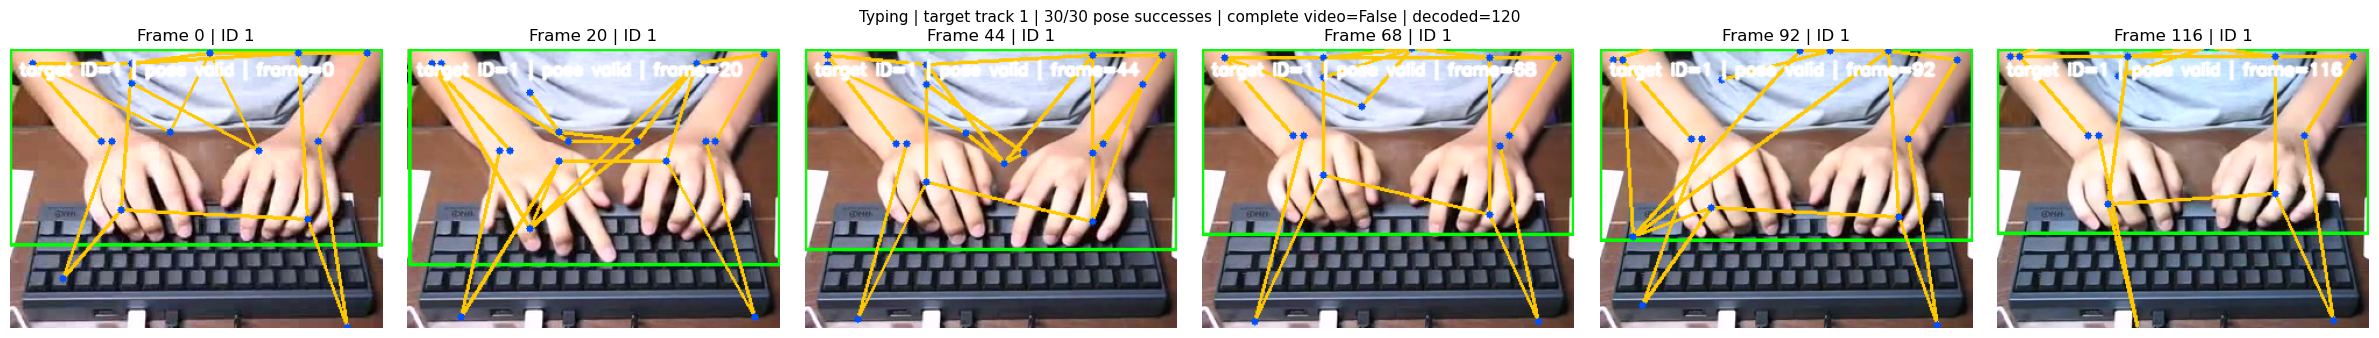

Saved review image: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\visualizations\tracked_pose_pilot_review_v1\Typing_pilot_review.png
Track observation counts (ID, observations): [(1, 30)]
Selected target ID: 1

REVIEW: Knitting | v_Knitting_g01_c01.avi


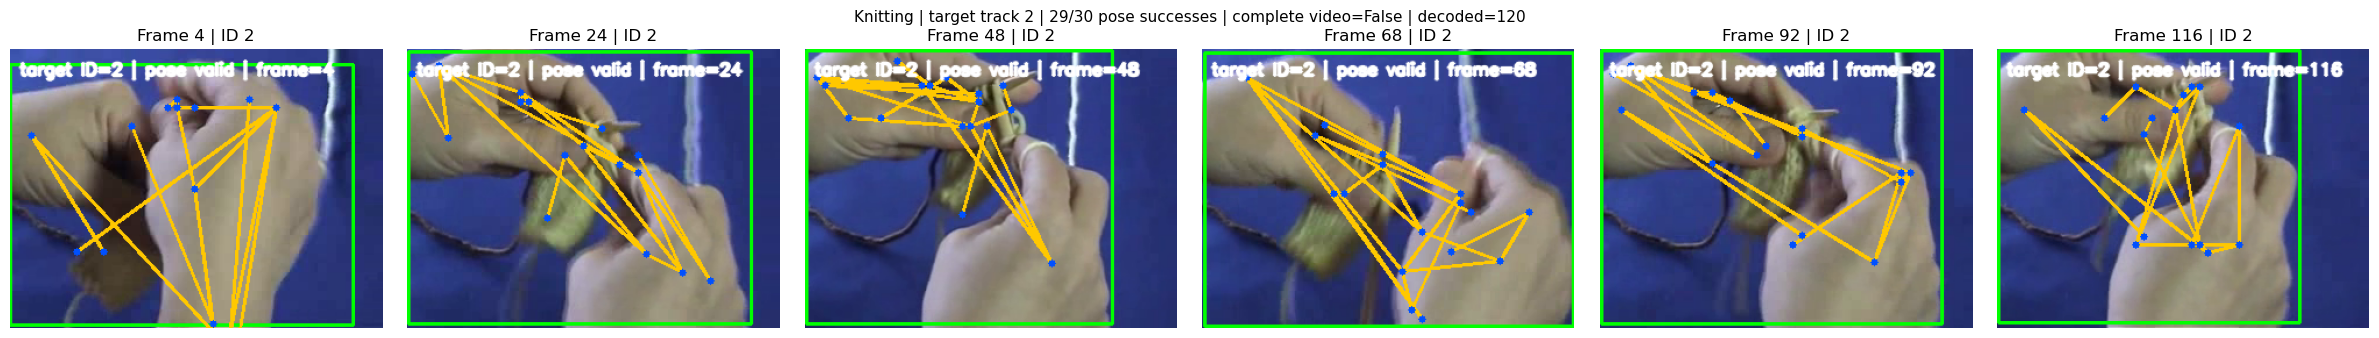

Saved review image: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\visualizations\tracked_pose_pilot_review_v1\Knitting_pilot_review.png
Track observation counts (ID, observations): [(2, 29), (1, 2)]
Selected target ID: 2

REVIEW: BoxingPunchingBag | v_BoxingPunchingBag_g01_c01.avi


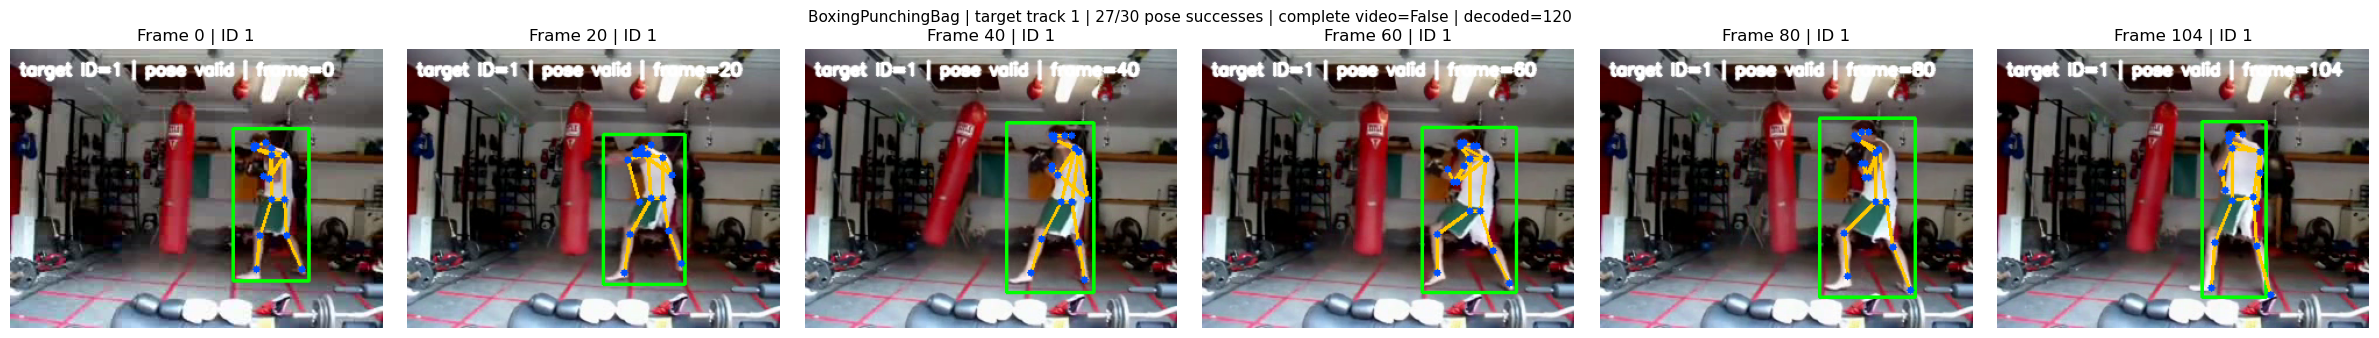

Saved review image: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\visualizations\tracked_pose_pilot_review_v1\BoxingPunchingBag_pilot_review.png
Track observation counts (ID, observations): [(1, 27), (3, 4), (6, 4), (8, 3), (4, 2), (9, 2), (2, 1)]
Selected target ID: 1

REVIEW: Biking | v_Biking_g01_c01.avi


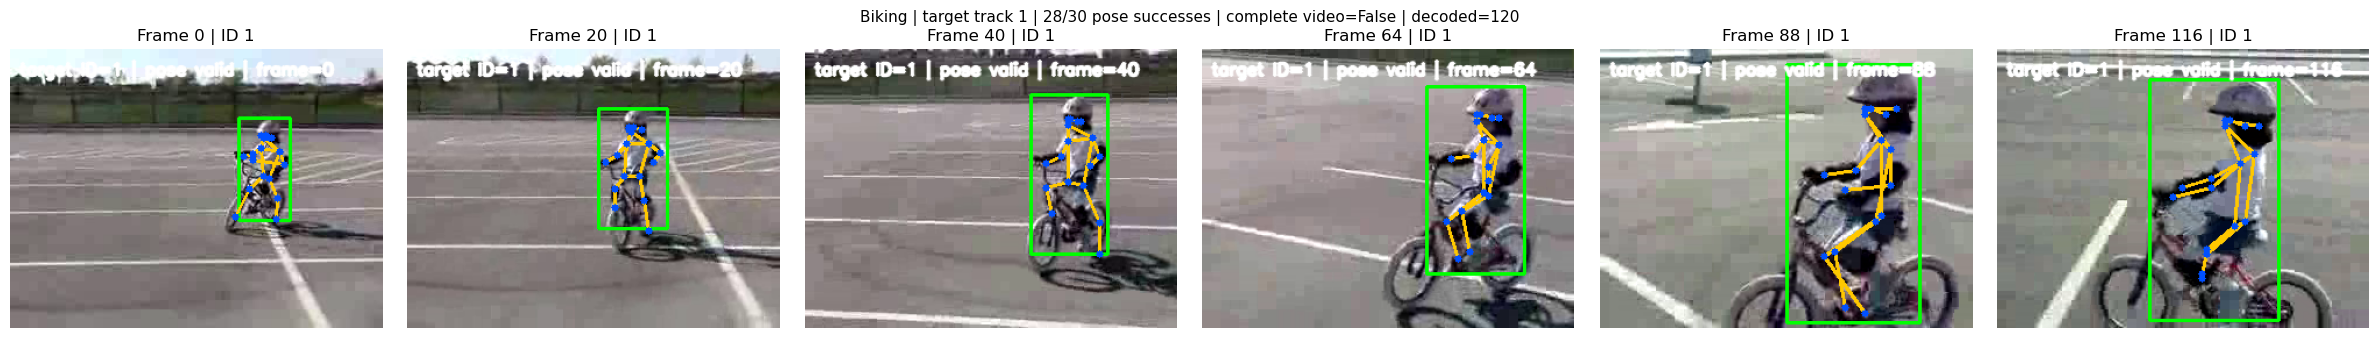

Saved review image: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\visualizations\tracked_pose_pilot_review_v1\Biking_pilot_review.png
Track observation counts (ID, observations): [(1, 28), (4, 2), (2, 1), (7, 1)]
Selected target ID: 1

REVIEW: Rowing | v_Rowing_g01_c01.avi


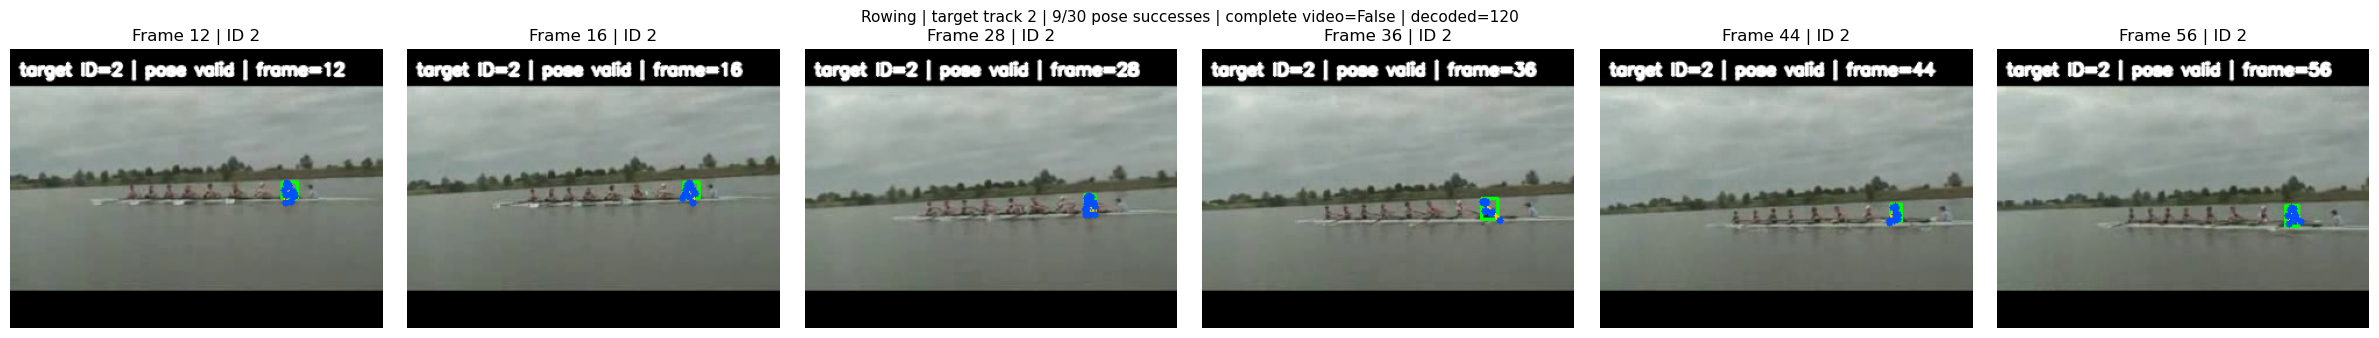

Saved review image: C:\Users\admin\ViTPose_Action_Recognition\Notebook_2_Improved_v2\outputs\visualizations\tracked_pose_pilot_review_v1\Rowing_pilot_review.png
Track observation counts (ID, observations): [(2, 9), (18, 7), (4, 4), (23, 3), (36, 3), (48, 3), (35, 2), (42, 2), (56, 2), (3, 1)]
Selected target ID: 2


In [4]:
# Review each of the five pilot videos.
# This cell only reads existing videos and NPZs and saves small PNG review sheets.
for _, row in report.iterrows():
    print("\n" + "=" * 80)
    print("REVIEW:", row["label"], "|", Path(str(row["video_path"])).name)
    render_video_review(row, max_frames=6)


## Decision before full extraction

Check that the green box encloses the intended actor and that the yellow/blue skeleton follows that same actor in all displayed frames.

- Typing / Knitting: check wrists, elbows and shoulders.
- BoxingPunchingBag: check that the target is the boxer, not a background person.
- Biking: check that the same cyclist remains selected.
- Rowing: this pilot reported a low pose-success rate. Do not approve full extraction for this class until the previews look credible.

**All five pilot NPZs are partial clips** (`complete_video=False`) because the pilot intentionally stopped at 120 decoded frames. That is expected. Do not use these five partial files to train or report UCF101 accuracy.

After reviewing, the next step is to run full extraction with `RUN_FULL_MANIFEST=True` and `MAX_DECODED_FRAMES=0` in `03_tracked_pose_extraction_IOU.ipynb`, but only after deciding whether the custom IoU association is acceptable. Notebook 04 must also be pointed at `tracked_keypoints_iou_v3` before it is run; its current default path points to the earlier `tracked_keypoints_v2` folder.